# How wrong is Forward Euler, and when does it matter?

**Question:** The engine advances the SIR equations in quarter-day steps with the simplest scheme there is. By how much do its peak and its final size differ from the exact ones for the epidemic case, does that matter for the cases on file, and what would a better answer cost?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can write one Forward Euler step by hand and find it in the engine's first step, measure the engine's error against two exact references that share no code with it, read the order of the scheme from how the error shrinks with the step, and judge for which cases and which quantities a quarter-day step is accurate enough. You also see how to remove most of the error without a better integrator.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import peak_frac
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

## Method

Forward Euler advances the state along its tangent for h days, evaluating all three rates at the previous state. Its global error is first order under smoothness and stability conditions (Hairer, Norsett and Wanner, 1993). The engine also clips susceptible and infected counts at zero; the later adverse-step experiment explains why that cannot guarantee conservation.

An accuracy reference must match the initial state. The independent final-size relation gives the infinite-time removed fraction once no infected people remain. For the continuous peak of the epidemic case, write s=S/N, i=I/N and s0=1-I0/N. The SIR first integral and peak condition give

$$s+i-\frac{\ln s}{R_0}=1-\frac{\ln s_0}{R_0},\qquad s_{\rm peak}=\frac1{R_0}.$$

For a positive seed with R0 s0>1, this yields

$$\frac{I_{\rm peak}}N=1-\frac{1+\ln(R_0s_0)}{R_0}.$$

This is a derived scalar reference for these initial conditions, not a second integrator implementation. The epidemic case meets the regime and reaches its peak within the horizon. The public `peak_frac` baseline instead describes the limit s0→1. Keeping both references exposes the offset caused by neglecting the initial 50 infected people (Kermack and McKendrick's system; Hethcote's SIR initial-state conditions).

First one step by hand, on the epidemic case with $\Delta t = 0.25$ days. The new infections are $\beta (N - I_0) I_0 \Delta t / N$ and the new recoveries $\gamma I_0 \Delta t$. The cell computes the three compartments after one step in plain arithmetic and prints them next to the first step of `simulate`. If the description of the scheme above is right, the two lines agree.

In [2]:
# one Forward Euler step by hand on the epidemic case, next to the first step the engine takes
p = params_of("EX02_epidemic")
dt = 0.25
new_infections = p.beta / p.N * (p.N - p.I0) * p.I0 * dt
new_recoveries = p.gamma * p.I0 * dt
by_hand = [p.N - p.I0 - new_infections, p.I0 + new_infections - new_recoveries, new_recoveries]
engine = simulate(p, dt)
print("by hand  ", [round(v, 3) for v in by_hand])
print("engine ", [round(v[1], 3) for v in (engine.S, engine.I, engine.R)])

by hand   [99943.128, 54.372, 2.5]
engine  [99943.128, 54.372, 2.5]


The two lines are the same to three decimals: the engine is the textbook scheme and nothing else. Now the question of how far that scheme is from the truth. The next cell runs the engine on the epidemic case at five steps, from a whole day down to a sixteenth of a day, and compares each run with the two exact references. It prints the number of steps each run takes, which is the cost, next to the removed fraction and the peak it produced.

In [3]:
# Match the analytic peak to the finite initial state before measuring discretization error.
p = params_of("EX02_epidemic")
steps = [1.0, 0.5, 0.25, 0.125, 0.0625]
r0 = p.beta / p.gamma
exact_attack = final_size(r0, p.I0 / p.N)
small_seed_peak = peak_frac(r0) * p.N
exact_peak = p.N * (1 - (1 + np.log(r0 * (1 - p.I0 / p.N))) / r0)
attack_error = []
peak_error = []
for dt in steps:
    r = simulate(p, dt)
    attack_error.append(r.attack_rate - exact_attack)
    peak_error.append(r.peak_I / exact_peak - 1)
    print(f"dt={dt:6.4f}, {len(r.t)-1:5d} steps, removed={r.attack_rate:.6f}, peak={r.peak_I:.3f}")
print(f"infinite removed fraction={exact_attack:.6f}, finite-initial-state peak={exact_peak:.5f}")
print(f"small-seed peak={small_seed_peak:.5f}, reference offset={exact_peak/small_seed_peak-1:.8f}")

dt=1.0000,   160 steps, removed=0.933717, peak=28844.564
dt=0.5000,   320 steps, removed=0.926912, peak=27835.559
dt=0.2500,   640 steps, removed=0.923654, peak=27345.239
dt=0.1250,  1280 steps, removed=0.922060, peak=27106.790
dt=0.0625,  2560 steps, removed=0.921271, peak=26987.800
infinite removed fraction=0.920487, finite-initial-state peak=26869.06230
small-seed peak=26850.87594, reference offset=0.00067731


The removed fraction approaches the infinite-time limit 0.920487 as the step is refined. The peak is now compared with 26869.0623 people for the finite initial state, rather than 26850.8759 in the vanishing-seed limit. The relative reference offset 0.00067731 cannot disappear by refining the engine. The next figure therefore separates discretization error from an inappropriate reference choice.

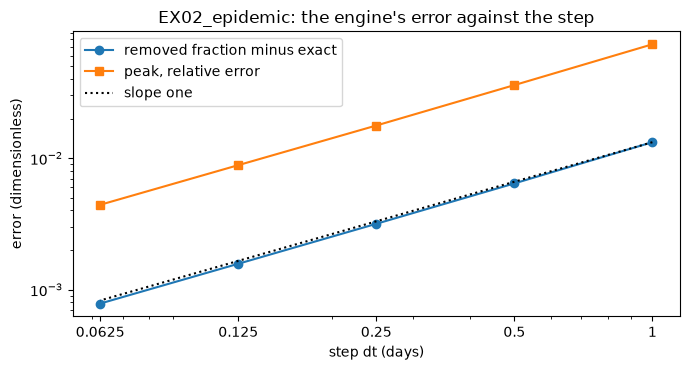

In [4]:
# draw the two errors against the step on log axes, with a line of slope one for comparison
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(steps, np.abs(attack_error), "o-", label="removed fraction minus exact")
ax.loglog(steps, np.abs(peak_error), "s-", label="peak, relative error")
ax.loglog(steps, np.array(steps) * attack_error[0] / steps[0], "k:", label="slope one")
ax.set_xticks(sorted(steps), [f"{value:g}" for value in sorted(steps)])
ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.set_xlabel("step dt (days)")
ax.set_ylabel("error (dimensionless)")
ax.set_title("EX02_epidemic: the engine's error against the step")
ax.legend()
fig.tight_layout()
plt.show()

On log axes both errors fall on straight lines parallel to the dotted line of slope one: every time the step is halved, the removed fraction error and the peak error are halved too, which is the signature of a first-order scheme. At the engine's own step of 0.25 days the removed fraction is high by about 0.003 and the peak by 1.8 percent, so the peak is the more sensitive of the two. The figure does not say where along the course the error is made, which is what the reference run below shows.

What would it cost to bring the peak within a tenth of a percent? If the error keeps shrinking in proportion to the step, the step has to shrink by the same factor. The cell extrapolates from the error at 0.25 days and prints the step it implies and the work it multiplies.

In [5]:
# Test the heuristic step explicitly instead of treating extrapolation as a certificate.
target_error = 0.001
per_day = peak_error[2] / steps[2]
needed = target_error / per_day
verified = simulate(p, needed)
achieved_error = abs(verified.peak_I / exact_peak - 1)
old_per_day = (engine.peak_I / small_seed_peak - 1) / steps[2]
old_needed = target_error / old_per_day
old_verified = simulate(p, old_needed)
old_achieved = abs(old_verified.peak_I / small_seed_peak - 1)
print(f"heuristic h={needed:.6f}, actual steps={len(verified.t)-1}, final day={verified.t[-1]:.6f}")
print(f"achieved finite-reference error={achieved_error:.8f}, target={target_error:.6f}")
print("target reached:", achieved_error <= target_error)
print(f"old small-seed heuristic h={old_needed:.6f}, achieved error={old_achieved:.8f}")

heuristic h=0.014107, actual steps=11342, final day=159.997777
achieved finite-reference error=0.00099495, target=0.001000
target reached: True
old small-seed heuristic h=0.013579, achieved error=0.00163549


The estimated 0.014107-day step is actually executed:11342 steps achieve relative error 0.00099495, below the 0.001 target against the continuous peak with the same initial state. This verifies this case, not every parameter choice or sampling phase. The earlier heuristic based on the vanishing-seed reference proposed 0.013579 days and achieved 0.00163549 against that reference, missing its target. Choosing the reference matters as much as extrapolating the error. To locate the time-course discrepancy next, the following cell builds a trajectory 32 times finer than the default step and aligns its samples with the coarse grids.

In [6]:
# a reference course from a step 32 times finer than the engine's, and the error of two coarser courses along the way
reference = simulate(p, 1 / 128)
reference_i = np.array(reference.I)
errors = {}
for dt in (1.0, 0.25):
    course = simulate(p, dt)
    errors[dt] = (np.array(course.I) - reference_i[:: round(dt * 128)]) / p.N
    worst = int(errors[dt].argmax())
    print(f"dt = {dt:4.2f}  largest {errors[dt][worst]:+.4f} on day {course.t[worst]:.2f}", end="  ")
    print(f"smallest {errors[dt].min():+.4f}")

dt = 1.00  largest +0.0660 on day 29.00  smallest -0.0749
dt = 0.25  largest +0.0154 on day 27.75  smallest -0.0195


The next cell draws the error of the infected curve along the horizon, as a share of the population, for the two courses.

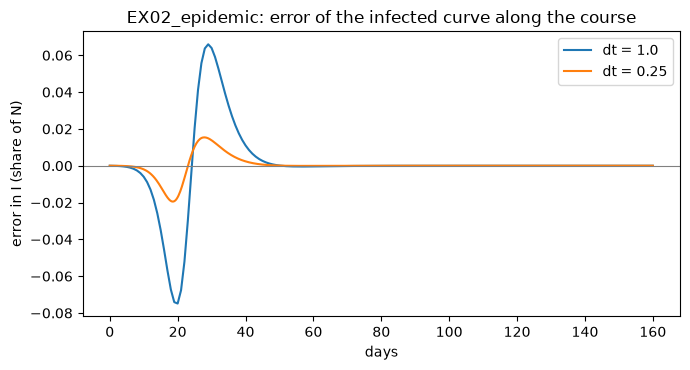

In [7]:
# draw the error of the infected curve along the horizon, as a share of the population
fig, ax = plt.subplots(figsize=(7, 3.8))
for dt, err in errors.items():
    ax.plot(np.arange(len(err)) * dt, err, label=f"dt = {dt}")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("days")
ax.set_ylabel("error in I (share of N)")
ax.set_title("EX02_epidemic: error of the infected curve along the course")
ax.legend()
fig.tight_layout()
plt.show()

The error of the infected curve has a signed shape: negative on the rising side and positive just after the peak, because the Euler hump arrives a little late and a little high. At the engine's step the largest error is 0.0154 of the population, on day 27.75, against 0.0660 at a one-day step, four times larger for a step four times larger. The error is greatest where the curve is steepest, as it must be for a scheme that follows the tangent. The figure does not contain the other four cases; the next cell does.

When does a quarter-day step matter? It depends on the case and on the quantity. The cell below runs every case that has infected people at the engine's step and at the fine step, and prints how much the engine's peak, the day of the peak and the removed fraction move. The reference here is the fine run and not the analytic formulas, so the numbers differ slightly from the earlier ones: the fine run has its own error, about 0.06 percent in the peak.

In [8]:
# the error of the engine's own step on every case that has infected people, against the finer reference
print(f"{'case':18s} {'peak err':>10s} {'day shift':>12s} {'removed err':>12s}")
for case_id in CASES:
    q = params_of(case_id)
    if q.I0 == 0:
        continue
    fine = simulate(q, 1 / 128)
    own = simulate(q)
    d_peak = own.peak_I / fine.peak_I - 1
    d_day = own.t_peak - fine.t_peak
    d_attack = own.attack_rate - fine.attack_rate
    print(f"{case_id:18s} {d_peak:+10.4f} {d_day:+12.2f} {d_attack:+12.5f}")

case                 peak err    day shift  removed err
EX01_subcritical      +0.0000        +0.00     +0.00000
EX02_epidemic         +0.0172        +0.79     +0.00307
EX03_fast_burn        +0.0322        +0.53     +0.00070
EX04_slow_spread      +0.0038        +0.32     +0.00051


The fast burn has the largest peak error, 3.2 percent, and the slow spread the smallest, 0.4 percent: the faster the dynamics, the more of the course a quarter-day step skips. The peak arrives 0.3 to 0.8 days late in the outbreak cases. The removed fraction is high by 0.003 at most, and the sub-critical peak remains its initial value even though its infected trajectory decays. Against the bands the example's cases declare (`expect` in `pipeline/cases/example_case.py`), an removed fraction between 0.90 and 0.95 for the epidemic, the step is harmless; for a decision that sizes capacity on the peak with a margin of a few percent, it is not.

Last, a way to improve the answer without touching the integrator. If the error is proportional to the step, three runs at $\Delta t$, $\Delta t / 2$ and $\Delta t / 4$ reveal the order from the ratio of their differences, and the last two runs extrapolate to a zero step: $2 x_{\Delta t/4} - x_{\Delta t/2}$ (Richardson extrapolation, see Hairer, Norsett and Wanner, 1993). The cell does this for the removed fraction, which the exact final size lets us judge.

In [9]:
# estimate the order of the scheme from three runs at dt, dt / 2 and dt / 4, with no exact answer needed
attack = [simulate(p, dt).attack_rate for dt in (0.5, 0.25, 0.125)]
order = np.log2((attack[0] - attack[1]) / (attack[1] - attack[2]))
extrapolated = 2 * attack[2] - attack[1]
print(f"estimated order: {order:.2f}")
print(f"finest run {attack[2]:.6f}, extrapolated {extrapolated:.6f}, exact {exact_attack:.6f}")

estimated order: 1.03
finest run 0.922060, extrapolated 0.920465, exact 0.920487


### A step and an error estimate have different meanings

For state $y=(S,I,R)$ in people, step $h$ in days and rate vector $f$ in people per day, the engine evaluates the following update. All rates use the state at the beginning of the interval; using a newly updated susceptible value in the infected equation would define another scheme.

$$y_{k+1}=y_k+h f(y_k),\qquad E_h=C h+O(h^2).$$

The second expression describes global error at a fixed physical time under smoothness and stability assumptions, not the error of a single arithmetic operation. If $A_h$ is the computed attack fraction, Richardson extrapolation removes its leading first-order term:

$$p_{\rm obs}=\log_2\!\left|\frac{A_h-A_{h/2}}{A_{h/2}-A_{h/4}}\right|,\qquad A_{\rm ext}=2A_{h/4}-A_{h/2}.$$

The observed order is meaningful only when the three runs represent the same endpoint and the differences exceed rounding noise. It is not a confidence interval. The independent final-size relation provides a second check on the extrapolated scalar; extrapolating every trajectory value could produce negative compartments and is not implemented here. These distinctions follow the numerical-analysis discussion in Hairer, Norsett and Wanner and explain why the notebook reports both convergence and the actual signed discrepancy.

### Sensitivity: positivity clipping can conceal an unstable step

Reducing the step studies consistency near the intended operating regime. Increasing it asks another question: does nonnegativity mean that the result is physically admissible? The engine clips susceptible and infected counts at zero, while recovery accumulates the full recovery increment. A large step can therefore remove a negative value without restoring conservation. The next experiment uses the same epidemic inputs and reports the largest population drift across the entire computed trajectory. It is an intentionally adverse numerical regime, not a suggested setting for a population model.

h= 0.25, max |(S+I+R)/N-1|=0.000000
h= 2.00, max |(S+I+R)/N-1|=0.000000
h= 8.00, max |(S+I+R)/N-1|=0.438756
h=16.00, max |(S+I+R)/N-1|=1.560599


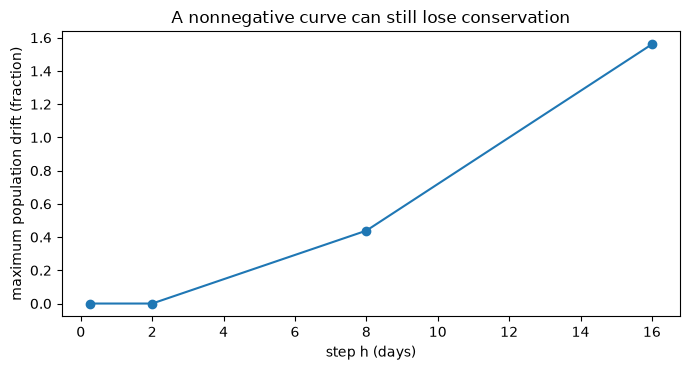

In [10]:
# Expose conservation loss that a positivity clamp alone cannot prevent.
adverse_steps = [0.25, 2.0, 8.0, 16.0]
mass_drift = []
for h in adverse_steps:
    adverse = simulate(p, h)
    mass = np.array(adverse.S) + np.array(adverse.I) + np.array(adverse.R)
    mass_drift.append(float(np.max(np.abs(mass / p.N - 1))))
    print(f"h={h:5.2f}, max |(S+I+R)/N-1|={mass_drift[-1]:.6f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(adverse_steps, mass_drift, "o-")
ax.set_xlabel("step h (days)")
ax.set_ylabel("maximum population drift (fraction)")
ax.set_title("A nonnegative curve can still lose conservation")
fig.tight_layout()
plt.show()

The adverse-step figure separates a nearly conserved default trajectory from coarse trajectories whose clipped increments no longer balance. Its vertical axis is a population fraction, so it should not be confused with infected-curve error in the earlier figure. Zero drift would still not prove an accurate peak: conservation is a necessary structural condition, whereas truncation error can remain substantial even when that condition holds. The correct response to a large drift is to reject the step or change the integration scheme, not to interpret the excess as additional infections.

### Use it on your own data

Begin with `data/examples/params.csv` and the params-record schema, whose rates are per day and whose counts are people. Pass a new table to `pipeline.stages.preprocess.run`; it returns accepted `SIRParams`, rejected rows with reasons and accepted-but-flagged extremes. Only accepted rows should reach `simulate(params, dt=...)`. Constructing the dataclass alone does not perform that ingestion check. Specify a positive integer horizon explicitly: the existing loader converts its optional `days` field and may substitute its default, so an assumed unit conversion must never be hidden there.

Choose the time step from the fastest rates, then run a refinement sequence while preserving the same initial state and final time. Inspect conservation, peak height, peak timing and residual infected people at the endpoint separately. A finite horizon cannot be compared blindly with an infinite-time attack fraction. Check the actual last time because the engine rounds the number of steps when the requested horizon is not divisible by the step. These checks establish numerical adequacy for the authored inputs only; they do not estimate contact rates, account for heterogeneous contacts or turn this deterministic example into a forecast.

## Results

**Answer:** The default Euler peak is 27345.239 people against 26869.062 for the continuous finite-initial-state reference, about 1.77 percent high. The 160-day removed fraction is 0.923654 against the infinite-time limit 0.920487. The heuristic 0.014107-day step is executed and achieves relative error 0.00099495, below 0.001; the earlier vanishing-seed attempt achieved 0.00163549 and missed that target. Extrapolation becomes a measured result only after running the proposed step against the appropriate reference.

The removed-fraction order estimate is 1.03, and extrapolating the 0.5/0.25/0.125-day runs gives 0.920465. These numbers concern the epidemic case, completed within its horizon. There is no universal accuracy across this family: faster rates, sampled peak timing and the cutoff alter the discrepancy. Conservation also cannot establish peak accuracy; the adverse-step figure further shows that clipping negatives can leave a nonconservative trajectory.

## Summary

- The hand calculation and engine agree on the first Euler step.
- The peak reference must include the finite initial state; the vanishing-seed limit has a different value.
- The proposed step is evaluated explicitly and meets this case's target without making the heuristic a general guarantee.
- Extrapolation reduces removed-fraction error when the outbreak ends within the horizon.
- The next comparison studies higher-order schemes on the same equations.

## References

- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine, the oracle and the baseline of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`, `pipeline/model/baseline.py`).
- Hethcote (2000), SIR initial-state conditions: https://doi.org/10.1137/S0036144500371907
